# Part 3 - Customer Segmentation

import libraries:

In [56]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import openpyxl
import seaborn as sns

# from scipy.sparse import csr_matrix
# from sklearn.neighbors import NearestNeighbors
# from sklearn.metrics.pairwise import cosine_similarity

load cleaned data

In [57]:
df_cust = pd.read_csv("../data/online_retail_cleaned.csv")
df_cust.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,transactiontype
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,Purchase
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,Purchase
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,Purchase
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,Purchase
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,Purchase


In [58]:
print(df_cust.shape)

(401604, 10)


### 1.Feature Engineering

The dataset contains transactions, not customers. You must create customer-level features. Create an RFM table: 
-  Recency: How recently did the customer purchase? last transaction
-  Frequency:How often does the customer purchase? nb of invoice for one customer
-  Monetary: How much money did the customer spend?

RFM table summarizes historical transaction data for each customer.

In [59]:
print(df_cust.columns.to_list())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalPrice', 'transactiontype']


In [60]:
print(df_cust['InvoiceDate'].dtypes)

str


In [61]:
#handle the date
df_cust['InvoiceDate'] = pd.to_datetime(df_cust['InvoiceDate'])

In [62]:
print(df_cust['InvoiceDate'].dtypes)

datetime64[us]


In [63]:
df_cust['InvoiceNo'].isna().sum()

np.int64(0)

In [64]:
# 2. Set reference date (usually 1 day after the latest transaction), normalize : set 00:00:00
reference_date = df_cust['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)

# 3. Aggregate raw Recency, Frequency, and Monetary values
#Recency = Reference Date - Last Purchase Date

rfm = df_cust.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', lambda x: x[x > 0].sum())  #only positive values 
).reset_index()

# 4. Score from 1 to 5 (Note: lower Recency days = higher R_Score)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1], duplicates='drop')
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5], duplicates='drop')

# 5. Combine scores into a single RFM string
rfm['RFM_Segment'] = (
    rfm['R_Score'].astype(str) + 
    rfm['F_Score'].astype(str) + 
    rfm['M_Score'].astype(str)
)

print(rfm)

      CustomerID  Recency  Frequency  Monetary R_Score F_Score M_Score  \
0        12346.0      325          2  77183.60       1       2       5   
1        12347.0        2          7   4310.00       5       4       5   
2        12348.0       75          4   1797.24       2       3       4   
3        12349.0       18          1   1757.55       4       1       4   
4        12350.0      310          1    334.40       1       1       2   
...          ...      ...        ...       ...     ...     ...     ...   
4367     18280.0      277          1    180.60       1       2       1   
4368     18281.0      180          1     80.82       1       2       1   
4369     18282.0        7          3    178.05       5       3       1   
4370     18283.0        3         16   2045.53       5       5       5   
4371     18287.0       42          3   1837.28       3       3       4   

     RFM_Segment  
0            125  
1            545  
2            234  
3            414  
4            112

In [65]:
print(rfm['Frequency'].min(), rfm['Frequency'].max(), rfm['Frequency'].mean())

1 248 5.07548032936871


In [66]:
print(rfm['Recency'].min(), rfm['Recency'].max(), rfm['Recency'].mean())

0 373 91.58119853613907


In [67]:
rfm[rfm['Recency'] == 373].head()  #customers of recency = 373

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Segment
359,12791.0,373,1,192.60,1,1,1,111
552,13065.0,373,1,205.86,1,1,1,111
1046,13747.0,373,1,79.60,1,1,1,111
1334,14142.0,373,1,311.81,1,1,2,112
1405,14237.0,373,1,161.00,1,1,1,111


In [68]:
rfm[rfm['Recency'] == 0].head() #nearest transactions 

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Segment
61,12423.0,0,9,1859.31,5,5,4,554
71,12433.0,0,7,13375.87,5,4,5,545
139,12518.0,0,5,2056.89,5,4,5,545
146,12526.0,0,3,1316.66,5,3,4,534
261,12662.0,0,12,3849.78,5,5,5,555


### find top 5 customers with total price 

In [69]:
rfm.groupby(rfm['CustomerID'])['Monetary'].sum().nlargest(5)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
Name: Monetary, dtype: float64

After building RVM table, the next step is to turning this number into meaningful insights like customer groups, predictive insights,.. 

###  2. Modeling Decision

Why is clustering appropriate?  
Why is supervised learning not suitable?
Which clustering algorithm will you use?  

Supervised learning is not suitable model because the goal it not the predict a predefined label, our dataset doen't contain a label or target column, so this is an unsupervised learning problem, not supervised problem.  
So we choose clustering model since we are searching to find meannigful customer groups accourding to RVM table, using Recency, Frequency, Monetary columns as numerical features for K-means clustering algorithm.

#### K-means algorithm :  
suitable with costumer segmetation using num. features, and similarity calculation.  
choosing the number of clustering (k) is allowed.  
Simple to implemet, interpret and evaluate 



In [70]:
rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Segment
0,12346.0,325,2,77183.60,1,2,5,125
1,12347.0,2,7,4310.00,5,4,5,545
2,12348.0,75,4,1797.24,2,3,4,234
3,12349.0,18,1,1757.55,4,1,4,414
4,12350.0,310,1,334.40,1,1,2,112


In [71]:
#customerID is an identifier, not a feature 
X = rfm[['Recency', 'Frequency', 'Monetary']]

In [72]:
#explore data
X.describe()

,Recency,Frequency,Monetary
count,4372.000000,4372.000000,4372.000000
mean,91.581199,5.075480,2032.755923
std,100.772139,9.338754,8952.025481
min,0.000000,1.000000,0.000000
25%,16.000000,1.000000,302.175000
50%,50.000000,3.000000,659.435000
75%,143.000000,5.000000,1647.315000
max,373.000000,248.000000,280206.020000


In [73]:
print(X['Frequency'].mode())

0    1
Name: Frequency, dtype: int64


In [74]:
rfm[rfm['Frequency'] == 1].count()


CustomerID     1313
Recency        1313
Frequency      1313
Monetary       1313
R_Score        1313
F_Score        1313
M_Score        1313
RFM_Segment    1313
dtype: int64

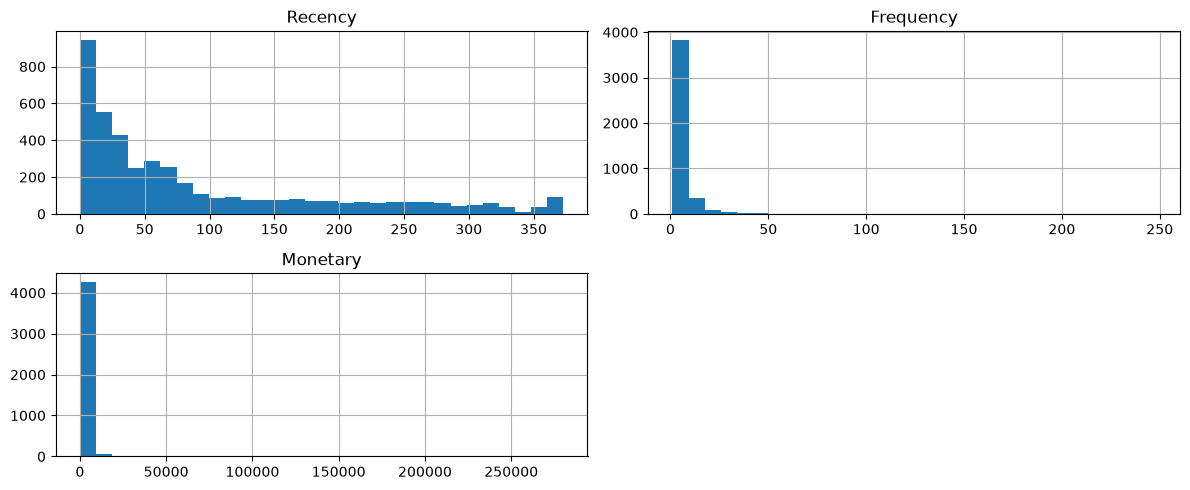

In [75]:
X.hist(figsize=(12, 5), bins=30)

plt.tight_layout()
plt.show()

In [76]:
X.skew()

Recency       1.249370
Frequency    11.412274
Monetary     19.408434
dtype: float64

### Intepretation : 
almost of histogram is concentrated in the left sides so high skewed (values > 0), to handle it :

In [77]:
X_log = X.copy()

X_log['Frequency'] = np.log1p(X_log['Frequency'])
X_log['Monetary'] = np.log1p(X_log['Monetary'])

In [78]:
X.min()

Recency      0.0
Frequency    1.0
Monetary     0.0
dtype: float64

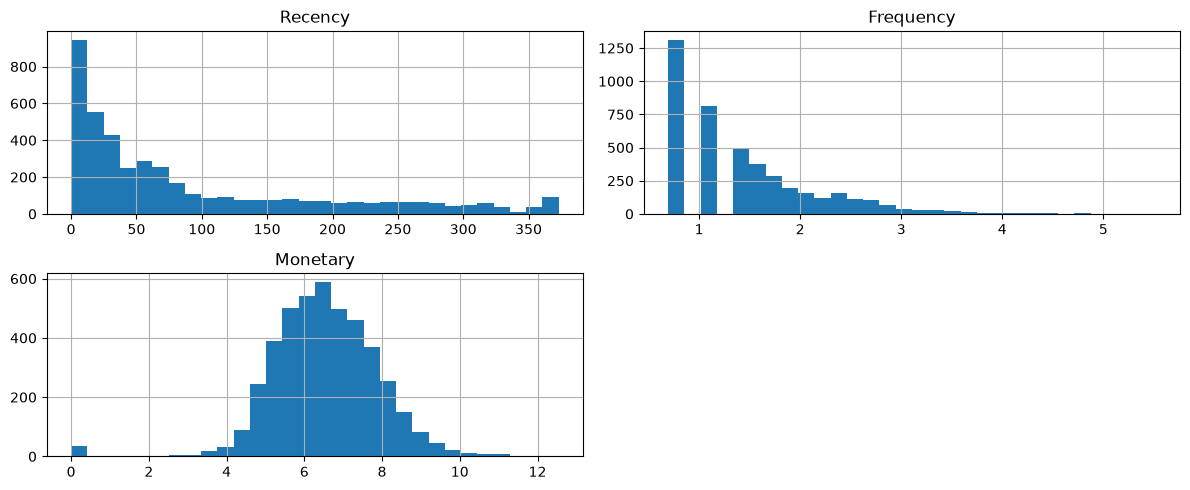

In [79]:
#revisualize data after handling negative values
X_log.hist(figsize=(12, 5), bins=30)
plt.tight_layout()
plt.show()

### Scale Features :  
scale features then return as dataframe 

In [80]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

In [81]:
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X_log.columns,
    index=X_log.index
)

X_scaled.head()

,Recency,Frequency,Monetary
0,2.316568,-0.467493,3.416462
1,-0.889050,0.864405,1.326709
2,-0.164560,0.226173,0.693370
3,-0.730258,-1.018087,0.677204
4,2.167700,-1.018087,-0.522977


### Find the optimal nb of clusters (k)

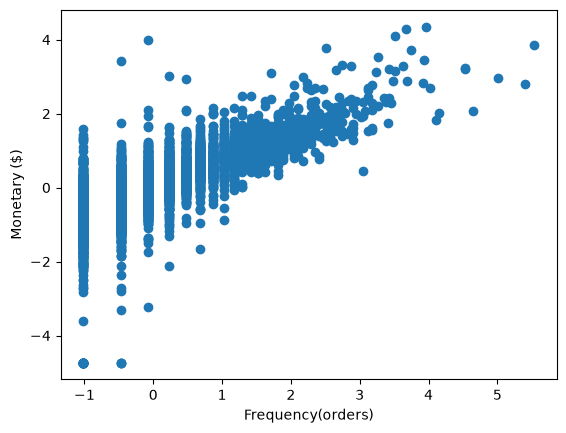

In [82]:
plt.scatter(X_scaled["Frequency"], X_scaled['Monetary'])
plt.xlabel('Frequency(orders)')
plt.ylabel('Monetary ($)')

plt.show()

In [83]:
# we start by choosing k =3 
from sklearn.cluster import KMeans

km_sample = KMeans(n_clusters = 3, random_state=42)
km_sample.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 3)","[

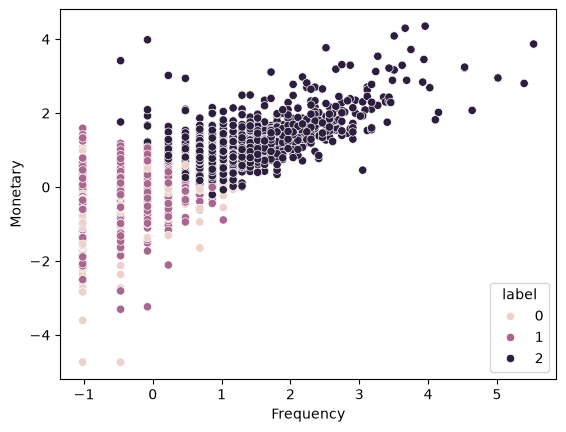

In [84]:
labels_sample = km_sample.labels_
X_scaled['label'] = labels_sample
sns.scatterplot(x= X_scaled['Frequency'], y=  X_scaled['Monetary'], hue='label', data= X_scaled)
plt.show()

In [85]:
print(X_scaled.min(), X_scaled.max())

Recency     -0.908899
Frequency   -1.018087
Monetary    -4.735271
label        0.000000
dtype: float64 Recency      2.792944
Frequency    5.532988
Monetary     4.350380
label        2.000000
dtype: float64


### Model Evaluation

Using Elbow Method :


In [86]:
from sklearn.cluster import KMeans        
from sklearn import metrics              
from scipy.spatial.distance import cdist

In [87]:
distortions = []
K = range(1, 9)
for k in K:
    kmeanModel = KMeans(n_clusters=k)
    kmeanModel.fit(X_scaled)
    # cdist computes the distance from every point to every centroid; we take the nearest one per point
    distortions.append(sum(np.min(cdist(X_scaled, kmeanModel.cluster_centers_, 'euclidean'), axis=1)) / X_scaled.shape[0])

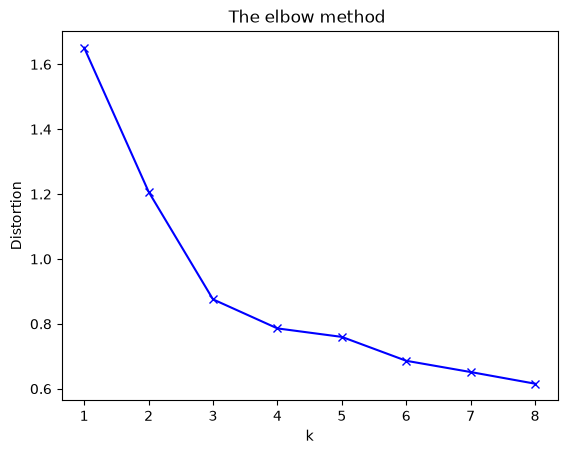

In [88]:
plt.plot(K, distortions, 'bx-')
plt.xlabel("k")
plt.ylabel("Distortion")
plt.title("The elbow method ")
plt.show()

### Interpretation :
Using Albow metode :The graph shows that a strong albow appears with k=3, so, we can select as a base number of clusters is 3, but this method is not enough.


Using Sillouette Score :

In [89]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.3f}")

K = 2, Silhouette Score = 0.418
K = 3, Silhouette Score = 0.485
K = 4, Silhouette Score = 0.444
K = 5, Silhouette Score = 0.388
K = 6, Silhouette Score = 0.401
K = 7, Silhouette Score = 0.364
K = 8, Silhouette Score = 0.359
K = 9, Silhouette Score = 0.345
K = 10, Silhouette Score = 0.346


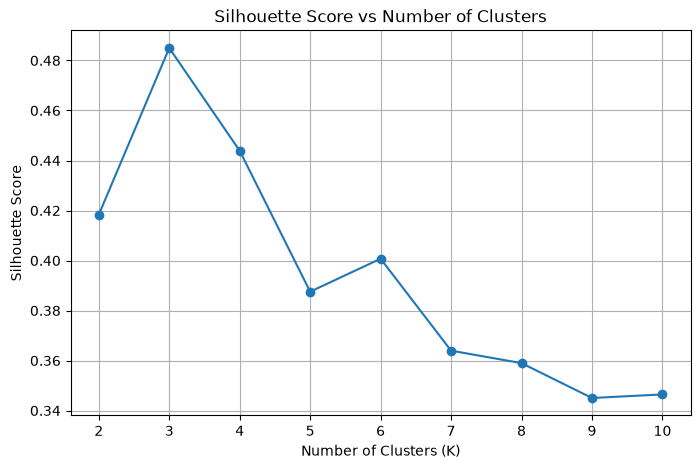

In [90]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), silhouette_scores, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs Number of Clusters')

plt.xticks(range(2, 11))
plt.grid()
plt.show()

Interpretation:   
using silouette method, the best nb of clusters is 3 clusters (the highest score), same result of albow method

Train the final model :

In [91]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(X_scaled)

Create cluster summary :

In [92]:
cluster_summary = rfm.groupby('Cluster').agg(
    
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

cluster_summary

,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,
0,55.22,2.30,614.78
1,29.18,11.82,5381.23
2,257.10,1.53,355.30


Convert cluster indices to  groups or clusters names based on recency,frequency, monetary scores(low, meduim, high):


• Champions: Recent, frequent, high-spending customers  
• Loyal Customers: Regular buyers with consistent purchases.  
• At Risk: Previously active but declining.


In [93]:
persona = {
    0: 'Champions', #high recency, high frequency, high monretary
    1: 'Loyal Customers', 
    2: 'At-Risk Customers' #high recency, low frequency, low/ meduim monetary 
}

rfm['Persona'] = rfm['Cluster'].map(persona)


In [94]:
rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Segment,Cluster,Persona
0,12346.0,325,2,77183.60,1,2,5,125,1,Loyal Customers
1,12347.0,2,7,4310.00,5,4,5,545,1,Loyal Customers
2,12348.0,75,4,1797.24,2,3,4,234,1,Loyal Customers
3,12349.0,18,1,1757.55,4,1,4,414,0,Champions
4,12350.0,310,1,334.40,1,1,2,112,2,At-Risk Customers


In [95]:
rfm.tail()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Segment,Cluster,Persona
4367,18280.0,277,1,180.60,1,2,1,121,2,At-Risk Customers
4368,18281.0,180,1,80.82,1,2,1,121,2,At-Risk Customers
4369,18282.0,7,3,178.05,5,3,1,531,0,Champions
4370,18283.0,3,16,2045.53,5,5,5,555,1,Loyal Customers
4371,18287.0,42,3,1837.28,3,3,4,334,0,Champions


Intepretation : 
champions : high recency, high frequency, high monetary  
loyal customer : moderate(recent, frequency, monetary) 2 of features >=2  
at risk customer : 2 of features = 1


In [96]:
per_champions = (rfm['Persona'] == 'Champions').sum() / len(rfm) *100
per_champions

np.float64(47.049405306495885)

In [97]:
x = rfm['Persona'].unique()
x

<StringArray>
['Loyal Customers', 'Champions', 'At-Risk Customers']
Length: 3, dtype: str

In [98]:
per_loyal = (rfm['Persona'] == 'Loyal Customers').sum() / len(rfm) *100
per_loyal

np.float64(30.946935041171088)

In [99]:
per_risk = (rfm['Persona'] == 'At-Risk Customers').sum() / len(rfm) *100
print(per_risk)

22.00365965233303


In [100]:
((rfm['F_Score'] == 1) & (rfm['R_Score'] == 5)).sum() 

np.int64(42)

After grouping customer in 3 groups, we conclude that:    
47% are champions customers.
30% are loyal customers.  
22% are at risk. 
There is 42 new customers.

In [101]:
rfm.to_csv('customer_segmentation.csv', index=False)

In [102]:
segmented_data = pd.read_csv('customer_segmentation.csv')

segmented_data.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Segment,Cluster,Persona
0,12346.0,325,2,77183.60,1,2,5,125,1,Loyal Customers
1,12347.0,2,7,4310.00,5,4,5,545,1,Loyal Customers
2,12348.0,75,4,1797.24,2,3,4,234,1,Loyal Customers
3,12349.0,18,1,1757.55,4,1,4,414,0,Champions
4,12350.0,310,1,334.40,1,1,2,112,2,At-Risk Customers


## Part 4 — PCA Visualization

Visualize customer segments. Apply PCA to reduce your customer features into 2 dimensions.

PCA is used to reduce features(recency,frequency,monetary) into 2-dimensions so we can visualize it. 
<!-- How much variance is retained.
Whether the visualization supports your clustering results. -->

In [103]:
segmented_data['CustomerID']

0       12346.0
1       12347.0
2       12348.0
3       12349.0
4       12350.0
         ...   
4367    18280.0
4368    18281.0
4369    18282.0
4370    18283.0
4371    18287.0
Name: CustomerID, Length: 4372, dtype: float64

In [104]:
#select features 
features = segmented_data[['Recency', 'Frequency', 'Monetary']]

In [105]:
from sklearn.decomposition import PCA

features_log = features.copy()
features_log[['Frequency', 'Monetary']] = np.log1p(
    features_log[['Frequency', 'Monetary']]
)

X_scaled = scaler.transform(features_log)

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [106]:
# conbert to dataframe 
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

pca_df['Cluster'] = segmented_data['Cluster'].values

How much variance is retained?

In [107]:
explained_variance = pca.explained_variance_ratio_

print(explained_variance)
print(f"Total variance retained: {explained_variance.sum() * 100:.2f}%")

[0.7149596  0.20880296]
Total variance retained: 92.38%


so, the model reserve ~92% of the variance of the original features. (good score ~1 )

### Visualization in 2D

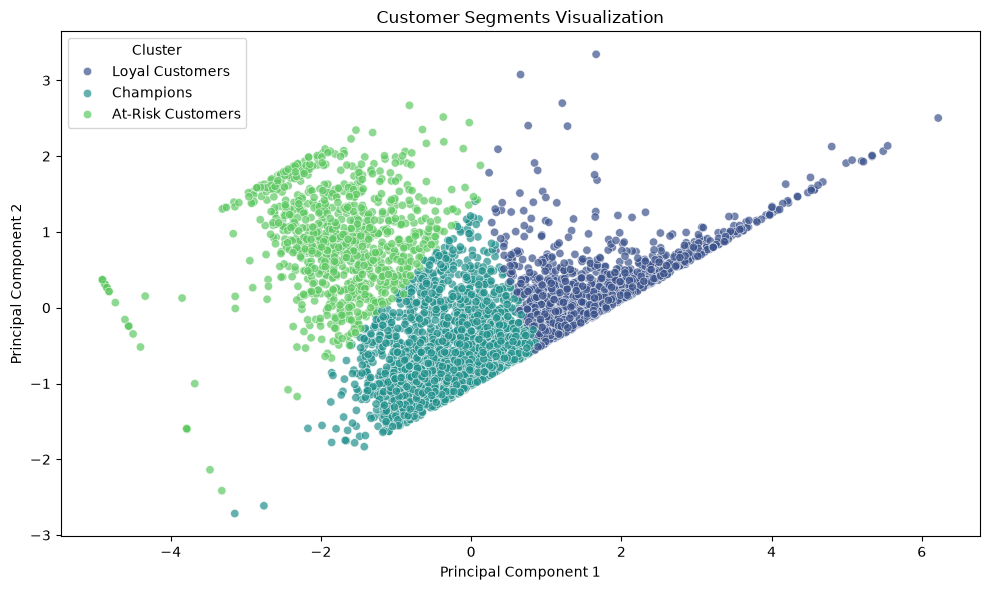

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue=segmented_data['Persona'],
    palette='viridis',
    alpha=0.7
)

plt.title('Customer Segments Visualization')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

In [112]:
pca.components_

array([[-0.49604336,  0.61490872,  0.61304832],
       [ 0.86823682,  0.34289779,  0.35858881]])

Intepretation :


Customers are clearly separeted in 3 clusters(champions, loyal, at risk customer) based on distance clustering not density. The graph shows some ovelap indicating some difference behaviors  but also presence of similarety but these clusers.

In [114]:
plt.savefig('customer_segments_pca.png', dpi=300, bbox_inches='tight')
plt.show()

<Figure size 640x480 with 0 Axes>